# Valoración de opciones con Monte Carlo y Black-Scholes
**Alan Jesús Hernández Soto**

In [46]:
import numpy as np
import matplotlib.pyplot as plt

Simulacion de Monte Carlo de precio en tiempo T de una accion

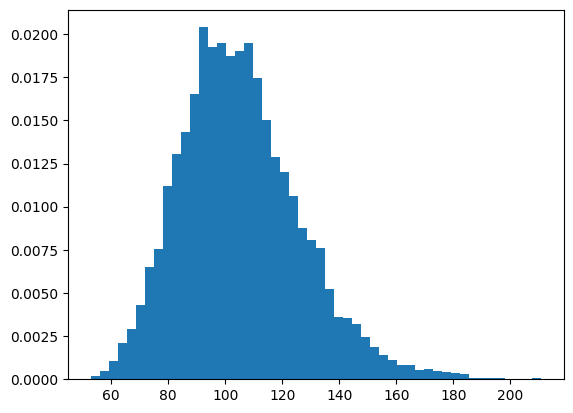

In [ ]:
def s(r, sigma, T, S0):
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * np.random.normal(0, 1))

np.random.seed(125)
list = []
for i in range(10000):
    list.append(s(110, 0.05, 0.2, 1, 100))

plt.hist(list, bins=50, density=True)
plt.show()


In [48]:
print(np.mean(list))
print(np.std(list))

105.2698405214625
21.202158646854826


In [49]:
#Intervalo de confianza

lim_inf = np.mean(list) - 1.96*(np.std(list)*np.sqrt(1))
lim_sup = np.mean(list) + 1.96*(np.std(list)*np.sqrt(1))

print(f'Intervalo de confianza: [{lim_inf}, {lim_sup}]')

Intervalo de confianza: [63.71360957362704, 146.82607146929797]


Obtencion de el valor presente de las posibles ganancias de la opcion

In [52]:
ganancias=[]
for i in range(len(list)):
    if list[i] > 110:
        ganancias.append(list[i]-110)
    else:
        ganancias.append(0)

ganancias = np.array(ganancias)
pv = ganancias*np.exp(-0.05*1)
np.mean(pv)

np.float64(6.055423916474732)

Metodo Black-Scholes para la obtencion justa de una accion

In [51]:
from scipy.stats import norm
d1 = (np.log(100/110) + (0.05 + (0.2**2)/2)*1)/(0.2*np.sqrt(1))
d2 = d1 - 0.2*np.sqrt(1)
call_price = 100*norm.cdf(d1) - 110*np.exp(-0.05*1)*norm.cdf(d2)
print(call_price)

6.040088129724239
